# Author vs. CTann comparison using the CTann supertree

This notebook extends the strict CL-ID benchmark by asking how a non-exact CTann annotation is positioned relative to the author annotation in the supplied CTann supertree.

**Important mapping rule:** annotation-to-supertree mapping is **CL-ID only**. A text label is retained for readability and human review, but it is never used to automatically map a missing CL ID to a supertree node.

The final relationship categories are:

- `EXACT`
- `CTANN_NARROWER_THAN_AUTHOR`
- `CTANN_BROADER_THAN_AUTHOR`
- `DIFFERENT_BRANCH`
- `UNMAPPED`

`EXACT + CTANN_NARROWER_THAN_AUTHOR + CTANN_BROADER_THAN_AUTHOR` is reported separately as hierarchy-compatible agreement.

## 0. Imports

In [55]:
from pathlib import Path
import re
import collections
import difflib

import pandas as pd
import numpy as np
import networkx as nx

## 1. Configuration

In [56]:
# Main anatomogram cell-instance file.
CELL_INSTANCES = Path("anatomogram-sc-transcriptomics-cell-instances.csv.gz")

# Fallback used by the local project layout.
if not CELL_INSTANCES.exists():
    candidate = Path("../anatomogram-data/anatomogram-sc-transcriptomics-cell-instances.csv.gz")
    if candidate.exists():
        CELL_INSTANCES = candidate

# Supertree is stored in the local Downloads folder.
SUPERTREE = (
    Path.home()
    / "Downloads"
    / "merged-ctann-level-mapping-table-vccf-expert-slim-hierarchy- NV - ctann-level-mapping-table-NV revisions_v10.csv"
)

if not CELL_INSTANCES.exists():
    raise FileNotFoundError(f"Cell-instance file not found: {CELL_INSTANCES}")
if not SUPERTREE.exists():
    raise FileNotFoundError(f"Supertree file not found: {SUPERTREE}")

OUTPUT_DIR = Path("ctann_supertree_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REVIEW_FILE = OUTPUT_DIR / "supertree_mapping_review.csv"

CL_RE = re.compile(r"^CL:\d+$")
LEVELS = list(range(1, 13))

print("Cell-instance input:", CELL_INSTANCES.resolve())
print("Supertree:", SUPERTREE.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Cell-instance input: /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/anatomogram-data/anatomogram-sc-transcriptomics-cell-instances.csv.gz
Supertree: /Users/sbidanta/Downloads/merged-ctann-level-mapping-table-vccf-expert-slim-hierarchy- NV - ctann-level-mapping-table-NV revisions_v10.csv
Output directory: /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/anatomogram-comparison/ctann_supertree_results


## 2. Helper functions

The helper functions below are reusable, but the notebook executes each analysis stage explicitly in later cells. There is no `main()` wrapper.

In [57]:
def norm_text(value):
    if pd.isna(value):
        return ""
    return " ".join(str(value).strip().lower().split())


def is_cl(value):
    return bool(CL_RE.match(str(value).strip())) if not pd.isna(value) else False

## 3. Validate and clean the supertree structure

This step repairs only structural problems that can be inferred from the supertree itself (for example, shifted label/ID columns or a malformed ID cell whose correct ID occurs elsewhere in the same hierarchy). It does **not** map author or CTann annotations by label.

In [58]:
def clean_supertree(path):
    df = pd.read_csv(path, dtype=str)
    fixes = []

    # A. Detect a CL ID in the label column and text in the ID column.
    for level in LEVELS:
        label_col = f"AS/{level}"
        id_col = f"AS/{level}/ID"
        label2_col = f"AS/{level}/LABEL"
        if label_col not in df.columns or id_col not in df.columns:
            continue

        mask = df[label_col].map(is_cl) & ~df[id_col].map(is_cl) & df[id_col].notna()
        for idx in df.index[mask]:
            old_label = df.at[idx, label_col]
            old_id = df.at[idx, id_col]
            new_label = old_id
            new_id = old_label
            fixes.append((idx, label_col, old_label, new_label, "detected shifted label/ID"))
            fixes.append((idx, id_col, old_id, new_id, "detected shifted label/ID"))
            df.at[idx, label_col] = new_label
            df.at[idx, id_col] = new_id

            if label2_col in df.columns:
                old_label2 = df.at[idx, label2_col]
                if norm_text(old_label2) != norm_text(new_label):
                    fixes.append((idx, label2_col, old_label2, new_label, "aligned duplicate label after shift"))
                    df.at[idx, label2_col] = new_label

    # B. Within the supertree only, collect valid label -> ID evidence.
    label_to_ids = collections.defaultdict(set)
    for level in LEVELS:
        label_col = f"AS/{level}"
        id_col = f"AS/{level}/ID"
        label2_col = f"AS/{level}/LABEL"
        if label_col not in df.columns or id_col not in df.columns:
            continue

        use_cols = [c for c in (label_col, id_col, label2_col) if c in df.columns]
        for _, row in df[use_cols].iterrows():
            cid = row.get(id_col)
            if not is_cl(cid):
                continue
            for c in (label_col, label2_col):
                if c in row.index:
                    label = norm_text(row.get(c))
                    if label:
                        label_to_ids[label].add(str(cid).strip())

    # C. Repair malformed/missing supertree IDs only when the same supertree
    # label has exactly one valid CL ID elsewhere in this same file.
    for level in LEVELS:
        label_col = f"AS/{level}"
        id_col = f"AS/{level}/ID"
        if label_col not in df.columns or id_col not in df.columns:
            continue

        for idx in df.index:
            current_id = df.at[idx, id_col]
            if is_cl(current_id):
                continue
            label = norm_text(df.at[idx, label_col])
            candidates = sorted(label_to_ids.get(label, set()))
            if label and len(candidates) == 1:
                new_id = candidates[0]
                fixes.append((idx, id_col, current_id, new_id, "unique ID inferred within supertree"))
                df.at[idx, id_col] = new_id

    fixes_df = pd.DataFrame(
        fixes,
        columns=["row_index", "column", "old_value", "new_value", "reason"],
    )
    return df, fixes_df

In [59]:
supertree_df, structural_fixes = clean_supertree(SUPERTREE)

print(f"Supertree rows: {len(supertree_df):,}")
print(f"Structural fixes inferred: {len(structural_fixes):,}")
display(structural_fixes)

Supertree rows: 1,468
Structural fixes inferred: 6


,row_index,column,old_value,new_value,reason
0,269,AS/9,CL:0002404,fetal thymocyte,detected shifted label/ID
1,269,AS/9/ID,fetal thymocyte,CL:0002404,detected shifted label/ID
2,269,AS/9/LABEL,NaN,fetal thymocyte,aligned duplicate label after shift
3,878,AS/4/ID,NaN,CL:0000499,unique ID inferred within supertree
4,7,AS/5/ID,epithelial cell of lower respiratory tract,CL:0002632,unique ID inferred within supertree
5,122,AS/6/ID,NaN,CL:0000169,unique ID inferred within supertree


## 4. Build the supertree graph

In [60]:
def build_supertree_index(df):
    node_labels = collections.defaultdict(collections.Counter)
    graph = nx.DiGraph()

    for _, row in df.iterrows():
        path = []
        for level in LEVELS:
            label_col = f"AS/{level}"
            id_col = f"AS/{level}/ID"
            label2_col = f"AS/{level}/LABEL"
            if label_col not in df.columns or id_col not in df.columns:
                continue

            cid = row.get(id_col)
            if not is_cl(cid):
                continue
            cid = str(cid).strip()

            for c in (label_col, label2_col):
                if c in df.columns:
                    value = row.get(c)
                    if not pd.isna(value) and str(value).strip():
                        node_labels[cid][str(value).strip()] += 1

            path.append(cid)

        compact = []
        for cid in path:
            if not compact or compact[-1] != cid:
                compact.append(cid)

        graph.add_nodes_from(compact)
        graph.add_edges_from(zip(compact, compact[1:]))

    canonical_label = {
        cid: counts.most_common(1)[0][0] if counts else cid
        for cid, counts in node_labels.items()
    }
    return graph, canonical_label

In [61]:
graph, canonical_label = build_supertree_index(supertree_df)

print(f"Supertree nodes: {graph.number_of_nodes():,}")
print(f"Supertree edges: {graph.number_of_edges():,}")

Supertree nodes: 710
Supertree edges: 709


## 5. Load the anatomogram annotations and audit CL-ID coverage

Every unique annotation CL ID is checked directly against the supertree. Labels are retained only to make the audit/review tables readable. They do not determine automatic mappings.

In [62]:
def load_annotations(path):
    cell_df = pd.read_csv(path, dtype=str)

    required = {"dataset", "organ", "tool", "cell", "cell_id", "cell_label"}
    missing = required - set(cell_df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    # Audit by CL ID. Labels are descriptive metadata only.
    audit = (
        cell_df.assign(
            original_cl_id=cell_df["cell_id"].fillna("").str.strip(),
            original_label=cell_df["cell_label"].fillna("").str.strip(),
        )
        .groupby("original_cl_id", dropna=False)
        .agg(
            annotation_count=("cell", "size"),
            observed_tools=("tool", lambda x: "|".join(sorted(set(x.dropna().astype(str))))),
            observed_labels=("original_label", lambda x: "|".join(sorted(set(v for v in x.astype(str) if v)))),
        )
        .reset_index()
    )
    return cell_df, audit

In [63]:
cell_df, annotation_audit = load_annotations(CELL_INSTANCES)
graph_nodes = set(graph.nodes)

annotation_audit["mapping_status"] = np.where(
    annotation_audit["original_cl_id"].isin(graph_nodes),
    "MAPPED",
    "REVIEW",
)
annotation_audit["mapping_method"] = np.where(
    annotation_audit["mapping_status"].eq("MAPPED"),
    "direct_cl_id",
    "missing_cl_id",
)
annotation_audit["mapped_cl_id"] = np.where(
    annotation_audit["mapping_status"].eq("MAPPED"),
    annotation_audit["original_cl_id"],
    "",
)
annotation_audit["mapped_label"] = annotation_audit["mapped_cl_id"].map(canonical_label).fillna("")

print("Unique annotation CL IDs:", len(annotation_audit))
print(annotation_audit["mapping_method"].value_counts(dropna=False).to_string())
display(annotation_audit[annotation_audit["mapping_status"].eq("REVIEW")])

Unique annotation CL IDs: 209
mapping_method
direct_cl_id     196
missing_cl_id     13


,original_cl_id,annotation_count,observed_tools,observed_labels,mapping_status,mapping_method,mapped_cl_id,mapped_label
0,ASCTB-TEMP:co-expression-cell,36,author,co-expression cell,REVIEW,missing_cl_id,,
1,ASCTB-TEMP:cycling-cell,61,author,cycling cell,REVIEW,missing_cl_id,,
2,ASCTB-TEMP:endothelial-cell-of-vascular-tree,41,author,endothelial cell of vascular tree,REVIEW,missing_cl_id,,
3,ASCTB-TEMP:transformed-epithelial-cell,180,author,transformed epithelial cell,REVIEW,missing_cl_id,,
12,CL:0000091,623,author,Kupffer cell,REVIEW,missing_cl_id,,
21,CL:0000178,34,pan-human-azimuth,Leydig cell,REVIEW,missing_cl_id,,
28,CL:0000313,12,frmatch,SMG serous (nasal),REVIEW,missing_cl_id,,
50,CL:0000777,239,author,mesangial cell,REVIEW,missing_cl_id,,
124,CL:0010003,36,frmatch,AT0,REVIEW,missing_cl_id,,
129,CL:0019001,95,celltypist|frmatch,SMG serous (bronchial)|pre-TB secretory,REVIEW,missing_cl_id,,


## 6. Create or apply the human-reviewed CL-ID crosswalk

Missing CL IDs are not resolved automatically from labels. The review file is a CL-ID crosswalk. A reviewer may use the displayed labels as biological context, but the pipeline applies a mapping only when `review_status` is `approved` and `reviewed_mapped_cl_id` is a valid node in the supplied supertree.

In [64]:
def suggest_labels_for_review(labels, canonical_label, top_n=5):
    """Advisory label suggestions for the human reviewer only.

    Suggestions are never applied automatically.
    """
    query = norm_text(labels.split("|")[0] if labels else "")
    if not query:
        return ""

    scored = []
    q_tokens = set(query.split())
    for cid, label in canonical_label.items():
        lab = norm_text(label)
        if not lab:
            continue
        seq = difflib.SequenceMatcher(None, query, lab).ratio()
        lab_tokens = set(lab.split())
        union = q_tokens | lab_tokens
        jaccard = len(q_tokens & lab_tokens) / len(union) if union else 0.0
        containment = 1.0 if (query in lab or lab in query) else 0.0
        score = 0.55 * seq + 0.35 * jaccard + 0.10 * containment
        scored.append((score, cid, label))

    scored.sort(reverse=True)
    return "|".join(f"{cid}::{label}::{score:.3f}" for score, cid, label in scored[:top_n])


def create_or_load_review(annotation_audit, review_file, canonical_label, graph):
    needs_review = annotation_audit[annotation_audit["mapping_status"].eq("REVIEW")].copy()
    needs_review["suggested_matches"] = needs_review["observed_labels"].map(
        lambda x: suggest_labels_for_review(x, canonical_label)
    )

    template_cols = [
        "original_cl_id",
        "observed_labels",
        "observed_tools",
        "annotation_count",
        "mapping_method",
        "suggested_matches",
        "review_status",
        "reviewed_mapped_cl_id",
        "reviewed_mapped_label",
        "review_notes",
    ]

    if review_file.exists():
        review = pd.read_csv(review_file, dtype=str).fillna("")
        for col in template_cols:
            if col not in review.columns:
                review[col] = ""
        review = review[template_cols]
    else:
        review = needs_review[[
            "original_cl_id",
            "observed_labels",
            "observed_tools",
            "annotation_count",
            "mapping_method",
            "suggested_matches",
        ]].copy()
        review["review_status"] = ""
        review["reviewed_mapped_cl_id"] = ""
        review["reviewed_mapped_label"] = ""
        review["review_notes"] = ""
        review.to_csv(review_file, index=False)

    valid_nodes = set(graph.nodes)
    approved = review[
        review["review_status"].str.lower().eq("approved")
        & review["reviewed_mapped_cl_id"].isin(valid_nodes)
    ].copy()

    blank_label = approved["reviewed_mapped_label"].eq("")
    approved.loc[blank_label, "reviewed_mapped_label"] = approved.loc[
        blank_label, "reviewed_mapped_cl_id"
    ].map(canonical_label)

    return review, approved


def apply_review(annotation_audit, approved_review, canonical_label):
    final_mapping = annotation_audit.copy()
    final_mapping["review_applied"] = False

    if approved_review.empty:
        return final_mapping

    crosswalk = approved_review.set_index("original_cl_id")["reviewed_mapped_cl_id"].to_dict()

    for idx, row in final_mapping.iterrows():
        mapped_id = crosswalk.get(row["original_cl_id"])
        if mapped_id:
            final_mapping.at[idx, "mapping_status"] = "MAPPED"
            final_mapping.at[idx, "mapping_method"] = "curated_cl_id_crosswalk"
            final_mapping.at[idx, "mapped_cl_id"] = mapped_id
            final_mapping.at[idx, "mapped_label"] = canonical_label.get(mapped_id, mapped_id)
            final_mapping.at[idx, "review_applied"] = True

    return final_mapping

In [65]:
review_table, approved_review = create_or_load_review(
    annotation_audit,
    REVIEW_FILE,
    canonical_label,
    graph,
)
final_mapping = apply_review(annotation_audit, approved_review, canonical_label)

print(f"CL IDs requiring review: {(annotation_audit['mapping_status'] == 'REVIEW').sum():,}")
print(f"Approved CL-ID crosswalk entries applied: {len(approved_review):,}")
print("Review file:", REVIEW_FILE.resolve())
display(review_table)

CL IDs requiring review: 13
Approved CL-ID crosswalk entries applied: 0
Review file: /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/anatomogram-comparison/ctann_supertree_results/supertree_mapping_review.csv


,original_cl_id,observed_labels,observed_tools,annotation_count,mapping_method,suggested_matches,review_status,reviewed_mapped_cl_id,reviewed_mapped_label,review_notes
0,ASCTB-TEMP:co-expression-cell,co-expression cell,author,36,missing_cl_id,CL:0000000::cell::0.475|CL:0002077::ecto-epith...,,,,
1,ASCTB-TEMP:cycling-cell,cycling cell,author,61,missing_cl_id,CL:4033069::cycling T cell::0.741|CL:4033068::...,,,,
2,ASCTB-TEMP:endothelial-cell-of-vascular-tree,endothelial cell of vascular tree,author,41,missing_cl_id,CL:0002139::endothelial cell of vascular tree:...,,,,
3,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,author,180,missing_cl_id,CL:0000066::epithelial cell::0.726|CL:0000244:...,,,,
4,CL:0000091,Kupffer cell,author,623,missing_cl_id,CL:0000000::cell::0.550|CL:0002204::tuft cell:...,,,,
5,CL:0000178,Leydig cell,pan-human-azimuth,34,missing_cl_id,CL:0009091::Leydig stem cell::0.681|CL:0000000...,,,,
6,CL:0000313,SMG serous (nasal),frmatch,12,missing_cl_id,CL:4052060::spinous cell::0.220|CL:4042008::fi...,,,,
7,CL:0000777,mesangial cell,author,239,missing_cl_id,CL:0000650::mesangial cell::1.000|CL:1000742::...,,,,
8,CL:0010003,AT0,frmatch,36,missing_cl_id,CL:0000233::platelet::0.200|CL:0000056::myobla...,,,,
9,CL:0019001,SMG serous (bronchial)|pre-TB secretory,celltypist|frmatch,95,missing_cl_id,CL:0002625::seminiferous tubule epithelial cel...,,,,


## 7. Pair author and CTann annotations and classify supertree relationships

Cells are paired using `(dataset, cell)`. The mapping lookup uses the annotation's original CL ID only. Labels do not participate in the lookup.

In [66]:
def build_mapping_lookup(final_mapping):
    return final_mapping.set_index("original_cl_id").to_dict(orient="index")


def classify_relationship(graph, author_id, pred_id):
    if not author_id or not pred_id:
        return "UNMAPPED"
    if author_id == pred_id:
        return "EXACT"
    if nx.has_path(graph, author_id, pred_id):
        return "CTANN_NARROWER_THAN_AUTHOR"
    if nx.has_path(graph, pred_id, author_id):
        return "CTANN_BROADER_THAN_AUTHOR"
    return "DIFFERENT_BRANCH"


def pair_and_classify(cell_df, final_mapping, graph):
    lookup = build_mapping_lookup(final_mapping)
    grouped = collections.defaultdict(dict)

    for _, row in cell_df.iterrows():
        key = (row["dataset"], row["cell"])
        grouped[key][row["tool"]] = row

    rows = []
    for (dataset, cell), tool_map in grouped.items():
        if "author" not in tool_map:
            continue

        author = tool_map["author"]
        author_original_id = str(author.get("cell_id") or "").strip()
        author_map = lookup.get(author_original_id, {})
        author_mapped_id = (
            author_map.get("mapped_cl_id", "")
            if author_map.get("mapping_status") == "MAPPED"
            else ""
        )

        for tool, pred in tool_map.items():
            if tool == "author":
                continue

            pred_original_id = str(pred.get("cell_id") or "").strip()
            pred_map = lookup.get(pred_original_id, {})
            pred_mapped_id = (
                pred_map.get("mapped_cl_id", "")
                if pred_map.get("mapping_status") == "MAPPED"
                else ""
            )

            rows.append({
                "dataset": dataset,
                "organ": author.get("organ", ""),
                "cell": cell,
                "tool": tool,
                "author_cl_id_original": author_original_id,
                "author_label_original": author.get("cell_label", ""),
                "author_mapping_method": author_map.get("mapping_method", "missing_mapping_record"),
                "author_supertree_cl_id": author_mapped_id,
                "author_supertree_label": author_map.get("mapped_label", ""),
                "ctann_cl_id_original": pred_original_id,
                "ctann_label_original": pred.get("cell_label", ""),
                "ctann_mapping_method": pred_map.get("mapping_method", "missing_mapping_record"),
                "ctann_supertree_cl_id": pred_mapped_id,
                "ctann_supertree_label": pred_map.get("mapped_label", ""),
                "raw_exact_cl_id": author_original_id == pred_original_id,
                "supertree_relationship": classify_relationship(graph, author_mapped_id, pred_mapped_id),
            })

    return pd.DataFrame(rows)

In [67]:
pairs = pair_and_classify(cell_df, final_mapping, graph)

print(f"Paired author-vs-CTann rows: {len(pairs):,}")
display(pairs.head())

Paired author-vs-CTann rows: 82,237


,dataset,organ,cell,tool,author_cl_id_original,author_label_original,author_mapping_method,author_supertree_cl_id,author_supertree_label,ctann_cl_id_original,ctann_label_original,ctann_mapping_method,ctann_supertree_cl_id,ctann_supertree_label,raw_exact_cl_id,supertree_relationship
0,https://www.ebi.ac.uk/gxa/sc/experiments/E-MTA...,UBERON:0002107,SAMEA11294529-GATGAGGAGTGCTGCC,celltypist,CL:0000182,hepatocyte,direct_cl_id,CL:0000182,hepatocyte,CL:0000182,Hepatocytes,direct_cl_id,CL:0000182,hepatocyte,True,EXACT
1,https://www.ebi.ac.uk/gxa/sc/experiments/E-MTA...,UBERON:0002107,SAMEA11294529-GATGAGGAGTGCTGCC,pan-human-azimuth,CL:0000182,hepatocyte,direct_cl_id,CL:0000182,hepatocyte,CL:0000182,Hepatocyte,direct_cl_id,CL:0000182,hepatocyte,True,EXACT
2,https://www.ebi.ac.uk/gxa/sc/experiments/E-MTA...,UBERON:0002107,SAMEA11294529-GATGAGGAGTGCTGCC,popv,CL:0000182,hepatocyte,direct_cl_id,CL:0000182,hepatocyte,CL:0000182,hepatocyte,direct_cl_id,CL:0000182,hepatocyte,True,EXACT
3,https://www.ebi.ac.uk/gxa/sc/experiments/E-MTA...,UBERON:0002107,SAMEA11294529-GACCAATAGCCACCTG,celltypist,CL:0000182,hepatocyte,direct_cl_id,CL:0000182,hepatocyte,CL:0000182,Hepatocytes,direct_cl_id,CL:0000182,hepatocyte,True,EXACT
4,https://www.ebi.ac.uk/gxa/sc/experiments/E-MTA...,UBERON:0002107,SAMEA11294529-GACCAATAGCCACCTG,pan-human-azimuth,CL:0000182,hepatocyte,direct_cl_id,CL:0000182,hepatocyte,CL:0000182,Hepatocyte,direct_cl_id,CL:0000182,hepatocyte,True,EXACT


## 8. Level 1 — Overall ontology-aware comparison

In [68]:
RELATIONSHIPS = [
    "EXACT",
    "CTANN_NARROWER_THAN_AUTHOR",
    "CTANN_BROADER_THAN_AUTHOR",
    "DIFFERENT_BRANCH",
    "UNMAPPED",
]


def summarize_relationships(pairs):
    rows = []
    for tool, group in pairs.groupby("tool", sort=True):
        n = len(group)
        row = {
            "tool": tool,
            "paired_cells": n,
            "raw_exact_cl_id_n": int(group["raw_exact_cl_id"].sum()),
            "raw_exact_cl_id_rate": float(group["raw_exact_cl_id"].mean()) if n else np.nan,
        }

        for rel in RELATIONSHIPS:
            count = int((group["supertree_relationship"] == rel).sum())
            row[f"{rel.lower()}_n"] = count
            row[f"{rel.lower()}_rate"] = count / n if n else np.nan

        compatible = group["supertree_relationship"].isin([
            "EXACT",
            "CTANN_NARROWER_THAN_AUTHOR",
            "CTANN_BROADER_THAN_AUTHOR",
        ])
        row["hierarchy_compatible_n"] = int(compatible.sum())
        row["hierarchy_compatible_rate"] = float(compatible.mean()) if n else np.nan
        rows.append(row)

    return pd.DataFrame(rows)


level1 = summarize_relationships(pairs)
display(level1)

,tool,paired_cells,raw_exact_cl_id_n,raw_exact_cl_id_rate,exact_n,exact_rate,ctann_narrower_than_author_n,ctann_narrower_than_author_rate,ctann_broader_than_author_n,ctann_broader_than_author_rate,different_branch_n,different_branch_rate,unmapped_n,unmapped_rate,hierarchy_compatible_n,hierarchy_compatible_rate
0,azimuth,25285,5427,0.214633,5427,0.214633,14158,0.559937,30,0.001186,5027,0.198814,643,0.025430,19615,0.775756
1,celltypist,20311,8839,0.435183,8839,0.435183,1506,0.074147,2415,0.118901,6396,0.314903,1155,0.056866,12760,0.628231
2,pan-human-azimuth,16330,2326,0.142437,2326,0.142437,3239,0.198347,145,0.008879,9883,0.605205,737,0.045132,5710,0.349663
3,popv,20311,10384,0.511250,10384,0.511250,4409,0.217074,0,0.000000,4389,0.216090,1129,0.055586,14793,0.728325


## 9. Level 2 — Organ-level ontology-aware comparison

In [69]:
def summarize_by_organ(pairs):
    rows = []
    for (tool, organ), group in pairs.groupby(["tool", "organ"], sort=True):
        counts = group["supertree_relationship"].value_counts()
        n = len(group)
        rows.append({
            "tool": tool,
            "organ": organ,
            "paired_cells": n,
            "raw_exact_cl_id_rate": group["raw_exact_cl_id"].mean(),
            "exact_rate": counts.get("EXACT", 0) / n,
            "narrower_rate": counts.get("CTANN_NARROWER_THAN_AUTHOR", 0) / n,
            "broader_rate": counts.get("CTANN_BROADER_THAN_AUTHOR", 0) / n,
            "different_branch_rate": counts.get("DIFFERENT_BRANCH", 0) / n,
            "unmapped_rate": counts.get("UNMAPPED", 0) / n,
            "hierarchy_compatible_rate": (
                counts.get("EXACT", 0)
                + counts.get("CTANN_NARROWER_THAN_AUTHOR", 0)
                + counts.get("CTANN_BROADER_THAN_AUTHOR", 0)
            ) / n,
        })
    return pd.DataFrame(rows)


level2 = summarize_by_organ(pairs)
display(level2)

,tool,organ,paired_cells,raw_exact_cl_id_rate,exact_rate,narrower_rate,broader_rate,different_branch_rate,unmapped_rate,hierarchy_compatible_rate
0,azimuth,UBERON:0001264,2109,0.875771,0.875771,0.089142,0.007587,0.010431,0.017070,0.972499
1,azimuth,UBERON:0002048,3202,0.295440,0.295440,0.053092,0.004372,0.532167,0.114928,0.352904
2,azimuth,UBERON:0002113,19974,0.131871,0.131871,0.690898,0.000000,0.165265,0.011966,0.822770
3,celltypist,UBERON:0001264,2109,0.658132,0.658132,0.005216,0.000000,0.319583,0.017070,0.663348
4,celltypist,UBERON:0002048,3202,0.289819,0.289819,0.049969,0.051218,0.485946,0.123048,0.391006
5,celltypist,UBERON:0002107,15000,0.434867,0.434867,0.089000,0.150067,0.277733,0.048333,0.673933
6,pan-human-azimuth,UBERON:0001264,1268,0.602524,0.602524,0.152208,0.026025,0.190852,0.028391,0.780757
7,pan-human-azimuth,UBERON:0002048,1862,0.209452,0.209452,0.098281,0.034909,0.554780,0.102578,0.342642
8,pan-human-azimuth,UBERON:0002107,9049,0.120897,0.120897,0.313073,0.000332,0.510333,0.055365,0.434302
9,pan-human-azimuth,UBERON:0002113,4151,0.018791,0.018791,0.007227,0.010600,0.961214,0.002168,0.036618


## 10. Level 3 — Organ × author cell-type comparison

In [70]:
def summarize_by_organ_celltype(pairs):
    rows = []

    # Level 3 is defined by the original author CT.
    # Do not remove author CTs that are absent from the supertree.
    #
    # This preserves the same author reference classes used in the
    # strict benchmark, while the supertree columns describe whether
    # each class could be mapped.
    keys = [
        "tool",
        "organ",
        "author_cl_id_original",
        "author_label_original",
    ]

    for key, group in pairs.groupby(
        keys,
        sort=True,
        dropna=False,
    ):
        (
            tool,
            organ,
            author_cl_id,
            author_label,
        ) = key

        counts = (
            group["supertree_relationship"]
            .value_counts()
        )

        n = len(group)

        # For a given original author CL ID, the mapping should
        # resolve to at most one supertree node.
        mapped_ids = (
            group["author_supertree_cl_id"]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        mapped_ids = [
            value
            for value in mapped_ids.unique()
            if value
        ]

        mapped_labels = (
            group["author_supertree_label"]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        mapped_labels = [
            value
            for value in mapped_labels.unique()
            if value
        ]

        author_supertree_cl_id = (
            mapped_ids[0]
            if len(mapped_ids) == 1
            else ""
        )

        author_supertree_label = (
            mapped_labels[0]
            if len(mapped_labels) == 1
            else ""
        )

        author_mapping_status = (
            "MAPPED"
            if author_supertree_cl_id
            else "UNMAPPED"
        )

        exact_n = int(
            counts.get(
                "EXACT",
                0,
            )
        )

        narrower_n = int(
            counts.get(
                "CTANN_NARROWER_THAN_AUTHOR",
                0,
            )
        )

        broader_n = int(
            counts.get(
                "CTANN_BROADER_THAN_AUTHOR",
                0,
            )
        )

        different_branch_n = int(
            counts.get(
                "DIFFERENT_BRANCH",
                0,
            )
        )

        unmapped_n = int(
            counts.get(
                "UNMAPPED",
                0,
            )
        )

        hierarchy_compatible_n = (
            exact_n
            + narrower_n
            + broader_n
        )

        rows.append({
            "tool": tool,
            "organ": organ,

            # Original author annotation defines the Level 3 class.
            "author_cl_id_original": author_cl_id,
            "author_label_original": author_label,

            # Supertree mapping is retained separately.
            "author_supertree_cl_id": author_supertree_cl_id,
            "author_supertree_label": author_supertree_label,
            "author_mapping_status": author_mapping_status,

            "paired_cells": n,

            "exact_n": exact_n,
            "narrower_n": narrower_n,
            "broader_n": broader_n,
            "different_branch_n": different_branch_n,
            "unmapped_n": unmapped_n,

            "hierarchy_compatible_n": hierarchy_compatible_n,

            "exact_rate": exact_n / n,
            "narrower_rate": narrower_n / n,
            "broader_rate": broader_n / n,
            "different_branch_rate": different_branch_n / n,
            "unmapped_rate": unmapped_n / n,

            "hierarchy_compatible_rate": (
                hierarchy_compatible_n / n
            ),
        })

    return pd.DataFrame(rows)


level3 = summarize_by_organ_celltype(
    pairs
)

display(
    level3.head(30)
)

,tool,organ,author_cl_id_original,author_label_original,author_supertree_cl_id,author_supertree_label,author_mapping_status,paired_cells,exact_n,narrower_n,broader_n,different_branch_n,unmapped_n,hierarchy_compatible_n,exact_rate,narrower_rate,broader_rate,different_branch_rate,unmapped_rate,hierarchy_compatible_rate
0,azimuth,UBERON:0001264,ASCTB-TEMP:co-expression-cell,co-expression cell,,,UNMAPPED,36,0,0,0,0,36,0,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
1,azimuth,UBERON:0001264,CL:0000097,mast cell,CL:0000097,mast cell,MAPPED,7,0,0,7,0,0,7,0.000000,0.000000,1.000000,0.000000,0.0,1.000000
2,azimuth,UBERON:0001264,CL:0000115,endothelial cell,CL:0000115,endothelial cell,MAPPED,15,15,0,0,0,0,15,1.000000,0.000000,0.000000,0.000000,0.0,1.000000
3,azimuth,UBERON:0001264,CL:0000145,professional antigen presenting cell,CL:0000145,professional antigen presenting cell,MAPPED,4,0,0,4,0,0,4,0.000000,0.000000,1.000000,0.000000,0.0,1.000000
4,azimuth,UBERON:0001264,CL:0000169,type B pancreatic cell,CL:0000169,type B pancreatic cell,MAPPED,257,256,0,0,1,0,256,0.996109,0.000000,0.000000,0.003891,0.0,0.996109
5,azimuth,UBERON:0001264,CL:0000171,pancreatic A cell,CL:0000171,pancreatic A cell,MAPPED,857,850,0,5,2,0,855,0.991832,0.000000,0.005834,0.002334,0.0,0.997666
6,azimuth,UBERON:0001264,CL:0000173,pancreatic D cell,CL:0000173,pancreatic D cell,MAPPED,106,104,0,0,2,0,104,0.981132,0.000000,0.000000,0.018868,0.0,0.981132
7,azimuth,UBERON:0001264,CL:0000622,acinar cell,CL:0000622,acinar cell,MAPPED,181,0,173,0,8,0,173,0.000000,0.955801,0.000000,0.044199,0.0,0.955801
8,azimuth,UBERON:0001264,CL:0002079,pancreatic ductal cell,CL:0002079,pancreatic ductal cell,MAPPED,380,377,0,0,3,0,377,0.992105,0.000000,0.000000,0.007895,0.0,0.992105
9,azimuth,UBERON:0001264,CL:0002275,pancreatic PP cell,CL:0002275,pancreatic PP cell,MAPPED,190,189,0,0,1,0,189,0.994737,0.000000,0.000000,0.005263,0.0,0.994737


## 11. Mapping coverage

In [71]:
def summarize_mapping_coverage(cell_df, final_mapping):
    lookup = final_mapping.set_index("original_cl_id")["mapping_status"].to_dict()
    temp = cell_df[["tool", "cell_id"]].copy()
    temp["mapping_status"] = temp["cell_id"].fillna("").str.strip().map(lookup).fillna("REVIEW")

    rows = []
    for tool, group in temp.groupby("tool", sort=True):
        total = len(group)
        mapped = int(group["mapping_status"].eq("MAPPED").sum())
        rows.append({
            "tool": tool,
            "annotation_rows": total,
            "mapped_annotation_rows": mapped,
            "unmapped_annotation_rows": total - mapped,
            "mapped_annotation_rate": mapped / total if total else np.nan,
        })
    return pd.DataFrame(rows)


mapping_coverage = summarize_mapping_coverage(cell_df, final_mapping)
display(mapping_coverage)

,tool,annotation_rows,mapped_annotation_rows,unmapped_annotation_rows,mapped_annotation_rate
0,author,40285,38917,1368,0.966042
1,azimuth,36991,36991,0,1.000000
2,celltypist,23525,23433,92,0.996089
3,frmatch,1925,1861,64,0.966753
4,pan-human-azimuth,20893,20859,34,0.998373
5,popv,23525,23525,0,1.000000


## 12. Write outputs

In [72]:
structural_fixes.to_csv(OUTPUT_DIR / "supertree_structural_fixes.csv", index=False)
annotation_audit.to_csv(OUTPUT_DIR / "supertree_mapping_first_pass.csv", index=False)
final_mapping.to_csv(OUTPUT_DIR / "supertree_mapping_final.csv", index=False)
pairs.to_csv(OUTPUT_DIR / "ontology_pair_classification.csv.gz", index=False, compression="gzip")
level1.to_csv(OUTPUT_DIR / "ontology_level1_by_tool.csv", index=False)
level2.to_csv(OUTPUT_DIR / "ontology_level2_by_organ.csv", index=False)
level3.to_csv(OUTPUT_DIR / "ontology_level3_by_organ_celltype.csv", index=False)
mapping_coverage.to_csv(OUTPUT_DIR / "supertree_mapping_coverage.csv", index=False)

print("Wrote:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path)

Wrote:
 - ctann_supertree_results/figures
 - ctann_supertree_results/ontology_level1_by_tool.csv
 - ctann_supertree_results/ontology_level2_by_organ.csv
 - ctann_supertree_results/ontology_level3_by_organ_celltype.csv
 - ctann_supertree_results/ontology_pair_classification.csv.gz
 - ctann_supertree_results/supertree_mapping_coverage.csv
 - ctann_supertree_results/supertree_mapping_final.csv
 - ctann_supertree_results/supertree_mapping_first_pass.csv
 - ctann_supertree_results/supertree_mapping_review.csv
 - ctann_supertree_results/supertree_structural_fixes.csv


## 13. Meaningful visualizations

The plots below summarize the ontology-aware comparison at the same three levels used in the strict benchmark:

1. **Level 1 — supertree relationship distribution:** shows whether CTann annotations are exact, narrower, broader, on a different branch, or unmapped.
2. **Level 1 — strict exact vs supertree-aware agreement:** compares raw CL-ID agreement with supertree exact agreement and hierarchy-compatible agreement.
3. **Level 2 — organ × tool hierarchy-compatible heatmap:** shows how ontology-aware agreement varies across tissues.
4. **Level 3 — organ × cell-type hierarchy-compatible heatmap:** shows whether individual CTs are recovered consistently within their tissue context.
5. **Supertree mapping coverage:** shows how much of each annotation source can be represented in the supplied supertree.

`Hierarchy compatible` is defined as:

`EXACT + CTANN_NARROWER_THAN_AUTHOR + CTANN_BROADER_THAN_AUTHOR`

`DIFFERENT_BRANCH` and `UNMAPPED` are not included as hierarchy-compatible.

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# -----------------------------------------------------------------------------
# Visualization configuration
# -----------------------------------------------------------------------------

TOOL_ORDER = [
    "celltypist",
    "azimuth",
    "pan-human-azimuth",
    "popv",
]

TOOL_LABELS = {
    "author": "Author",
    "celltypist": "CellTypist",
    "azimuth": "Azimuth",
    "pan-human-azimuth": "Pan-Human Azimuth",
    "popv": "popV",
    "frmatch": "FR-Match",
}

ORG_NAMES = {
    "UBERON:0002107": "Liver",
    "UBERON:0001264": "Pancreas",
    "UBERON:0002113": "Kidney",
    "UBERON:0002048": "Lung",
}


# -----------------------------------------------------------------------------
# Publication-ready color palette
#
# Based on the colorblind-safe Okabe-Ito palette.
# Keep these colors fixed across all figures.
# -----------------------------------------------------------------------------

COLORS = {
    # Ontology relationships
    "exact": "#0072B2",               # blue
    "narrower": "#56B4E9",            # sky blue
    "broader": "#009E73",             # bluish green
    "different_branch": "#D55E00",    # vermillion
    "unmapped": "#999999",            # neutral gray

    # Comparison metrics
    "raw_exact": "#7F7F7F",           # gray
    "supertree_exact": "#0072B2",      # blue
    "compatible": "#009E73",           # green

    # General use
    "dark": "#222222",
    "light_gray": "#D9D9D9",
}


RELATIONSHIP_COLORS = {
    "Exact": COLORS["exact"],
    "CTann narrower": COLORS["narrower"],
    "CTann broader": COLORS["broader"],
    "Different branch": COLORS["different_branch"],
    "Unmapped": COLORS["unmapped"],
}


# Sequential palette for percentage heatmaps.
#
# A light-to-dark blue scale works well because all values
# represent increasing amounts of the same quantity.
HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "hra_blue",
    [
        "#F7FBFF",
        "#DEEBF7",
        "#9ECAE1",
        "#4292C6",
        "#08519C",
    ],
)


FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# -----------------------------------------------------------------------------
# Publication-friendly matplotlib defaults
# -----------------------------------------------------------------------------

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 120,

    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,

    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    "legend.fontsize": 9,
    "legend.title_fontsize": 9,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.linewidth": 0.8,
    "grid.linewidth": 0.6,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


print("Figures will be written to:", FIGURE_DIR.resolve())

Figures will be written to: /Users/sbidanta/projects/HRA/Publication/hra-ftu-explorer-supporting-information/anatomogram-comparison/ctann_supertree_results/figures


### 13.1 Level 1: Distribution of supertree relationships

This plot shows how the CTann predictions are related to the corresponding author annotations after both terms are placed in the supertree. Each bar represents all paired cells for one CTann tool and sums to 100%.

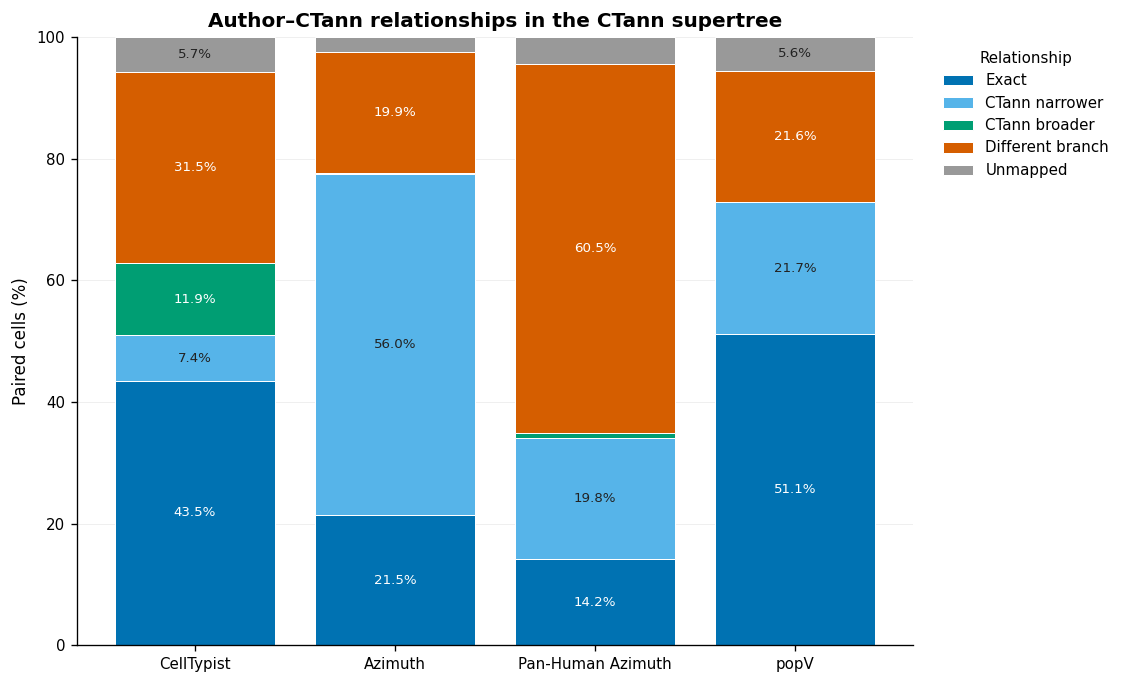

In [74]:
plot_tools = [
    tool
    for tool in TOOL_ORDER
    if tool in set(level1["tool"])
]

plot_df = (
    level1[level1["tool"].isin(plot_tools)]
    .set_index("tool")
    .reindex(plot_tools)
)


relationship_columns = [
    (
        "exact_rate",
        "Exact",
        COLORS["exact"],
    ),
    (
        "ctann_narrower_than_author_rate",
        "CTann narrower",
        COLORS["narrower"],
    ),
    (
        "ctann_broader_than_author_rate",
        "CTann broader",
        COLORS["broader"],
    ),
    (
        "different_branch_rate",
        "Different branch",
        COLORS["different_branch"],
    ),
    (
        "unmapped_rate",
        "Unmapped",
        COLORS["unmapped"],
    ),
]


x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))


fig, ax = plt.subplots(
    figsize=(9.5, 5.8)
)


for column, label, color in relationship_columns:

    values = (
        100
        * plot_df[column]
        .to_numpy(dtype=float)
    )

    bars = ax.bar(
        x,
        values,
        bottom=bottom,
        label=label,
        color=color,
        edgecolor="white",
        linewidth=0.6,
    )

    # Add labels only for reasonably large segments.
    for i, value in enumerate(values):

        if value >= 5:

            ax.text(
                x[i],
                bottom[i] + value / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
                color="white"
                if label
                in [
                    "Exact",
                    "CTann broader",
                    "Different branch",
                ]
                else COLORS["dark"],
            )

    bottom += values


ax.set_xticks(x)

ax.set_xticklabels(
    [
        TOOL_LABELS[t]
        for t in plot_df.index
    ]
)

ax.set_ylabel(
    "Paired cells (%)"
)

ax.set_ylim(
    0,
    100,
)

ax.set_title(
    "Author–CTann relationships in the CTann supertree"
)

ax.legend(
    title="Relationship",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

ax.grid(
    axis="y",
    alpha=0.20,
)

ax.set_axisbelow(True)


fig.tight_layout()


# Raster version
fig.savefig(
    FIGURE_DIR
    / "01_supertree_relationship_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

# Vector version for publication
fig.savefig(
    FIGURE_DIR
    / "01_supertree_relationship_distribution.pdf",
    bbox_inches="tight",
)

plt.show()

### 13.2 Level 1: Strict exact agreement versus supertree-aware agreement

The strict benchmark considers only identical original CL IDs. The supertree analysis can additionally identify annotations that map to the same supertree node or that have a direct ancestor–descendant relationship.

The comparison below shows:

- raw exact CL-ID agreement,
- exact agreement after mapping to the supertree,
- hierarchy-compatible agreement.

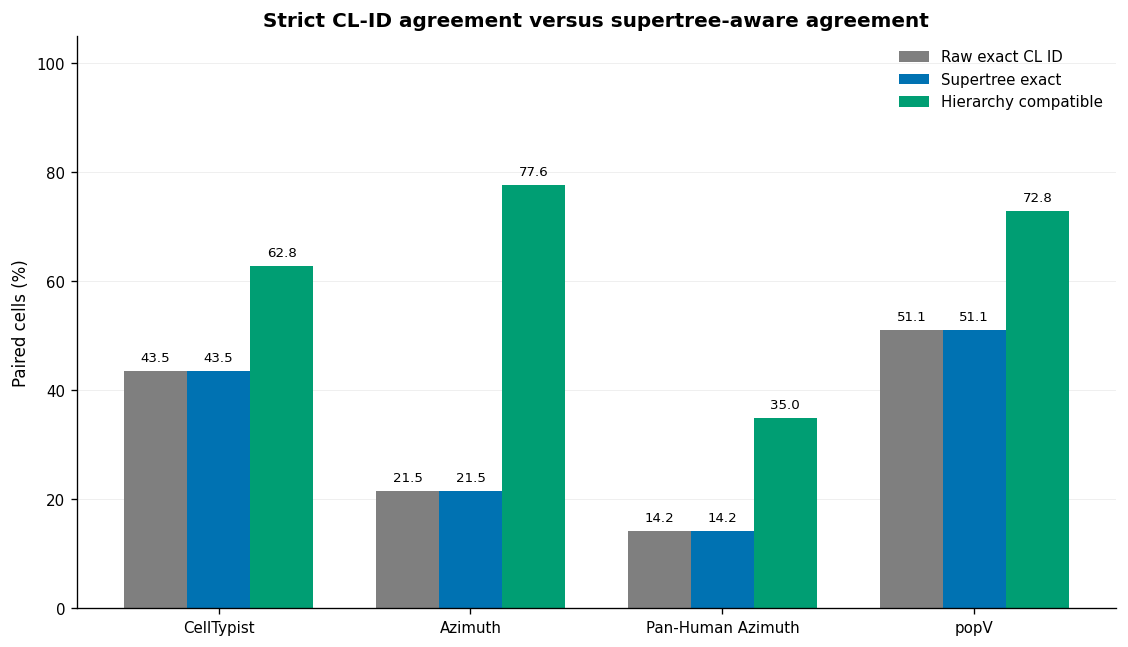

In [75]:
plot_df = (
    level1[
        level1["tool"].isin(
            TOOL_ORDER
        )
    ]
    .set_index("tool")
)


plot_order = [
    tool
    for tool in TOOL_ORDER
    if tool in plot_df.index
]

plot_df = plot_df.reindex(
    plot_order
)


x = np.arange(
    len(plot_df)
)

width = 0.25


raw_exact = (
    100
    * plot_df[
        "raw_exact_cl_id_rate"
    ]
    .to_numpy(dtype=float)
)

supertree_exact = (
    100
    * plot_df[
        "exact_rate"
    ]
    .to_numpy(dtype=float)
)

compatible = (
    100
    * plot_df[
        "hierarchy_compatible_rate"
    ]
    .to_numpy(dtype=float)
)


fig, ax = plt.subplots(
    figsize=(9.5, 5.5)
)


bars1 = ax.bar(
    x - width,
    raw_exact,
    width,
    label="Raw exact CL ID",
    color=COLORS["raw_exact"],
)

bars2 = ax.bar(
    x,
    supertree_exact,
    width,
    label="Supertree exact",
    color=COLORS["supertree_exact"],
)

bars3 = ax.bar(
    x + width,
    compatible,
    width,
    label="Hierarchy compatible",
    color=COLORS["compatible"],
)


ax.set_xticks(x)

ax.set_xticklabels(
    [
        TOOL_LABELS[t]
        for t in plot_df.index
    ]
)

ax.set_ylabel(
    "Paired cells (%)"
)

ax.set_ylim(
    0,
    105,
)

ax.set_title(
    "Strict CL-ID agreement versus supertree-aware agreement"
)


ax.legend(
    frameon=False,
)


ax.grid(
    axis="y",
    alpha=0.20,
)

ax.set_axisbelow(True)


for bars in [
    bars1,
    bars2,
    bars3,
]:

    for bar in bars:

        value = (
            bar.get_height()
        )

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            value + 1.3,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )


fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "02_strict_vs_supertree_agreement.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "02_strict_vs_supertree_agreement.pdf",
    bbox_inches="tight",
)

plt.show()

### 13.3 Level 2: Organ × tool hierarchy-compatible agreement

The organ-level heatmap shows the fraction of paired cells that are either exact matches or have a direct ancestor–descendant relationship in the supertree. This makes it possible to determine whether ontology-aware agreement differs substantially across tissues.

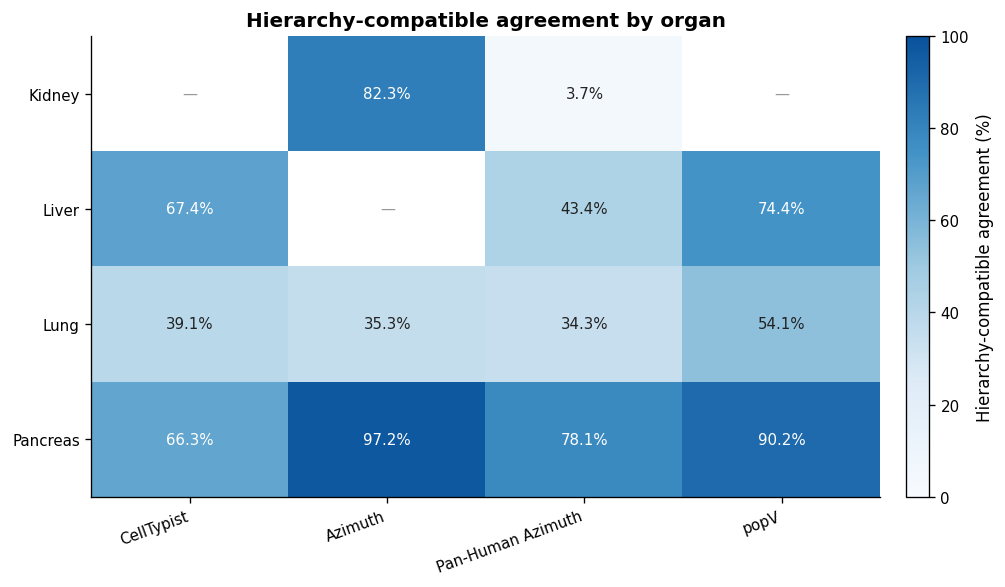

In [76]:
organ_df = level2.copy()


organ_df["organ_name"] = (
    organ_df["organ"]
    .map(ORG_NAMES)
    .fillna(organ_df["organ"])
)


organ_matrix = (
    organ_df[
        organ_df["tool"].isin(
            TOOL_ORDER
        )
    ]
    .pivot(
        index="organ_name",
        columns="tool",
        values="hierarchy_compatible_rate",
    )
    .reindex(
        columns=TOOL_ORDER
    )
)


preferred_order = [
    "Kidney",
    "Liver",
    "Lung",
    "Pancreas",
]


organ_order = [
    organ
    for organ in preferred_order
    if organ in organ_matrix.index
]


organ_order += [
    organ
    for organ in organ_matrix.index
    if organ not in organ_order
]


organ_matrix = (
    organ_matrix
    .reindex(
        organ_order
    )
)


values = (
    100
    * organ_matrix
    .to_numpy(dtype=float)
)

masked = np.ma.masked_invalid(
    values
)


fig, ax = plt.subplots(
    figsize=(8.5, 5)
)


im = ax.imshow(
    masked,
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap=HEATMAP_CMAP,
)


ax.set_xticks(
    np.arange(
        len(
            organ_matrix.columns
        )
    )
)

ax.set_xticklabels(
    [
        TOOL_LABELS[t]
        for t
        in organ_matrix.columns
    ],
    rotation=20,
    ha="right",
)


ax.set_yticks(
    np.arange(
        len(
            organ_matrix.index
        )
    )
)

ax.set_yticklabels(
    organ_matrix.index
)


ax.set_title(
    "Hierarchy-compatible agreement by organ"
)


for i in range(
    values.shape[0]
):

    for j in range(
        values.shape[1]
    ):

        value = values[i, j]

        if np.isfinite(
            value
        ):

            text_color = (
                "white"
                if value >= 60
                else COLORS["dark"]
            )

            ax.text(
                j,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color=text_color,
            )

        else:

            ax.text(
                j,
                i,
                "—",
                ha="center",
                va="center",
                fontsize=9,
                color=COLORS["unmapped"],
            )


cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.04,
    pad=0.03,
)

cbar.set_label(
    "Hierarchy-compatible agreement (%)"
)


fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "03_organ_tool_hierarchy_compatible_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "03_organ_tool_hierarchy_compatible_heatmap.pdf",
    bbox_inches="tight",
)

plt.show()

### 14.4 Level 3: Organ × cell-type hierarchy-compatible agreement

This heatmap keeps the organ context attached to each author CT. Each row represents an `organ × author CT` combination and each column represents a CTann tool.

To keep the figure readable, only well-supported organ–CT combinations are displayed. The complete Level 3 results remain available in `ontology_level3_by_organ_celltype.csv`.

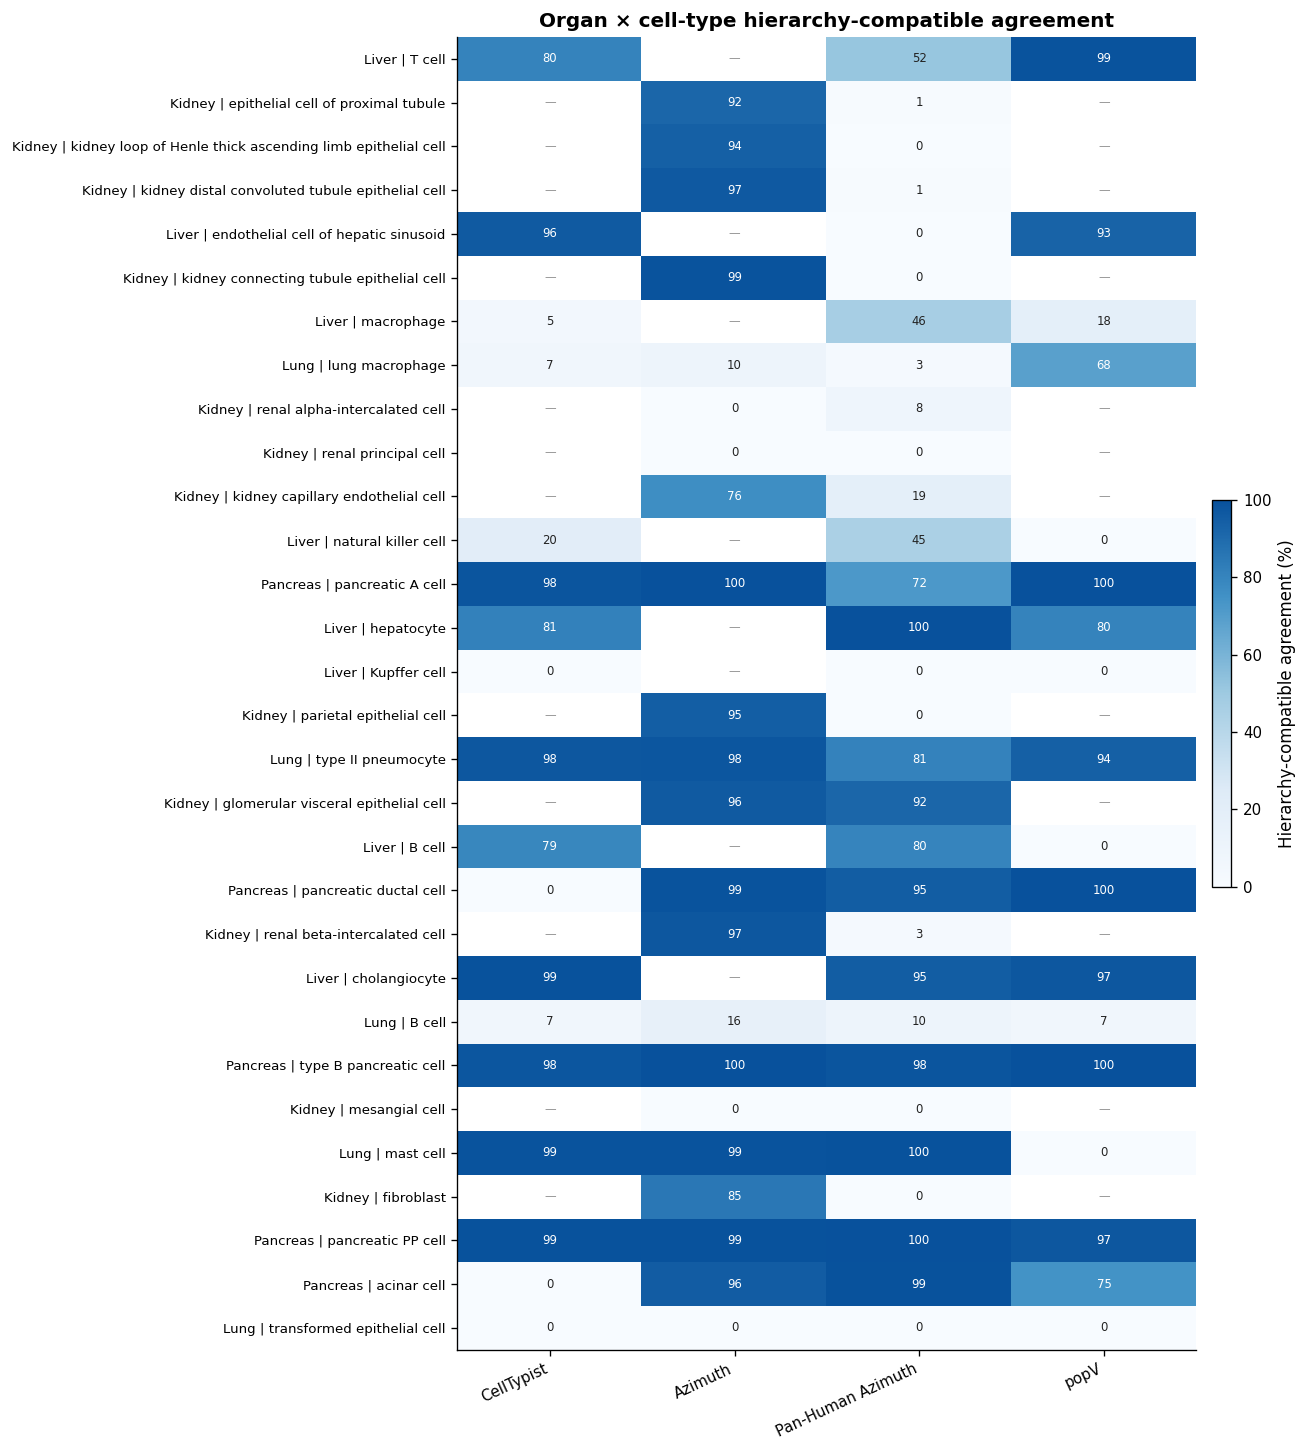

In [81]:
# -----------------------------------------------------------------------------
# Level 3 visualization:
# Organ × original author CT hierarchy-compatible agreement
# -----------------------------------------------------------------------------

MIN_CLASS_SUPPORT = 25
TOP_ORGAN_CT_CLASSES = 30


level3_plot = level3.copy()


# -----------------------------------------------------------------------------
# Organ names
# -----------------------------------------------------------------------------

level3_plot["organ_name"] = (
    level3_plot["organ"]
    .map(ORG_NAMES)
    .fillna(level3_plot["organ"])
)


# -----------------------------------------------------------------------------
# Stable class key
#
# IMPORTANT:
# Use the original author CL ID as the class identifier.
# Do not use the supertree ID here because unresolved author CTs do not
# have one.
# -----------------------------------------------------------------------------

level3_plot["organ_ct_key"] = (
    level3_plot["organ_name"].astype(str)
    + " | "
    + level3_plot["author_cl_id_original"].astype(str)
)


# Human-readable display label.
level3_plot["organ_ct_label"] = (
    level3_plot["organ_name"].astype(str)
    + " | "
    + level3_plot["author_label_original"].astype(str)
)


# -----------------------------------------------------------------------------
# Determine support for each organ × original author CT
#
# max() is used rather than sum() because different CTann tools can evaluate
# the same underlying author cell population.
# -----------------------------------------------------------------------------

class_support = (
    level3_plot
    .groupby(
        [
            "organ_ct_key",
            "organ_name",
            "author_cl_id_original",
            "author_label_original",
        ],
        as_index=False,
        dropna=False,
    )["paired_cells"]
    .max()
    .rename(
        columns={
            "paired_cells":
            "class_support"
        }
    )
)


class_support = (
    class_support[
        class_support["class_support"]
        >= MIN_CLASS_SUPPORT
    ]
    .sort_values(
        "class_support",
        ascending=False,
    )
    .head(
        TOP_ORGAN_CT_CLASSES
    )
)


# -----------------------------------------------------------------------------
# Keep only selected classes
# -----------------------------------------------------------------------------

selected_keys = (
    class_support["organ_ct_key"]
    .tolist()
)


plot_rows = (
    level3_plot[
        level3_plot["organ_ct_key"]
        .isin(selected_keys)
    ]
    .copy()
)


# -----------------------------------------------------------------------------
# Build hierarchy-compatible matrix
#
# 0.0 values remain 0.
# NaN means no paired cells for that tool × CT combination.
# -----------------------------------------------------------------------------

compatible_matrix = (
    plot_rows
    .pivot(
        index="organ_ct_key",
        columns="tool",
        values="hierarchy_compatible_rate",
    )
    .reindex(
        index=selected_keys,
        columns=TOOL_ORDER,
    )
)


# -----------------------------------------------------------------------------
# Build human-readable y-axis labels
# -----------------------------------------------------------------------------

label_lookup = (
    class_support
    .set_index("organ_ct_key")
)


display_labels = []

for key in compatible_matrix.index:

    row = label_lookup.loc[key]

    label = str(
        row["author_label_original"]
    ).strip()

    if not label:
        label = str(
            row["author_cl_id_original"]
        )

    display_labels.append(
        f"{row['organ_name']} | {label}"
    )


# -----------------------------------------------------------------------------
# Convert rates to percentages
# -----------------------------------------------------------------------------

values = (
    100
    * compatible_matrix.to_numpy(
        dtype=float
    )
)

masked = np.ma.masked_invalid(
    values
)


# -----------------------------------------------------------------------------
# Plot
# -----------------------------------------------------------------------------

fig_height = max(
    8,
    0.34
    * len(compatible_matrix.index)
    + 2,
)


fig, ax = plt.subplots(
    figsize=(11, fig_height)
)


im = ax.imshow(
    masked,
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap=HEATMAP_CMAP,
)


# -----------------------------------------------------------------------------
# Axes
# -----------------------------------------------------------------------------

ax.set_xticks(
    np.arange(
        len(compatible_matrix.columns)
    )
)

ax.set_xticklabels(
    [
        TOOL_LABELS[t]
        for t in compatible_matrix.columns
    ],
    rotation=25,
    ha="right",
)


ax.set_yticks(
    np.arange(
        len(compatible_matrix.index)
    )
)

ax.set_yticklabels(
    display_labels,
    fontsize=8,
)


ax.set_title(
    "Organ × cell-type hierarchy-compatible agreement"
)


# -----------------------------------------------------------------------------
# Cell labels
#
# Important distinction:
#
# 0     = paired cells exist, but hierarchy-compatible agreement is zero.
# —     = no paired cells exist for that tool × CT combination.
# -----------------------------------------------------------------------------

for i in range(values.shape[0]):

    for j in range(values.shape[1]):

        value = values[i, j]

        if np.isfinite(value):

            text_color = (
                "white"
                if value >= 60
                else COLORS["dark"]
            )

            ax.text(
                j,
                i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=7,
                color=text_color,
            )

        else:

            ax.text(
                j,
                i,
                "—",
                ha="center",
                va="center",
                fontsize=7,
                color=COLORS["unmapped"],
            )


# -----------------------------------------------------------------------------
# Colorbar
# -----------------------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.02,
)

cbar.set_label(
    "Hierarchy-compatible agreement (%)"
)


fig.tight_layout()


# -----------------------------------------------------------------------------
# Save
# -----------------------------------------------------------------------------

fig.savefig(
    FIGURE_DIR
    / "04_organ_celltype_hierarchy_compatible_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "04_organ_celltype_hierarchy_compatible_heatmap.pdf",
    bbox_inches="tight",
)


plt.show()

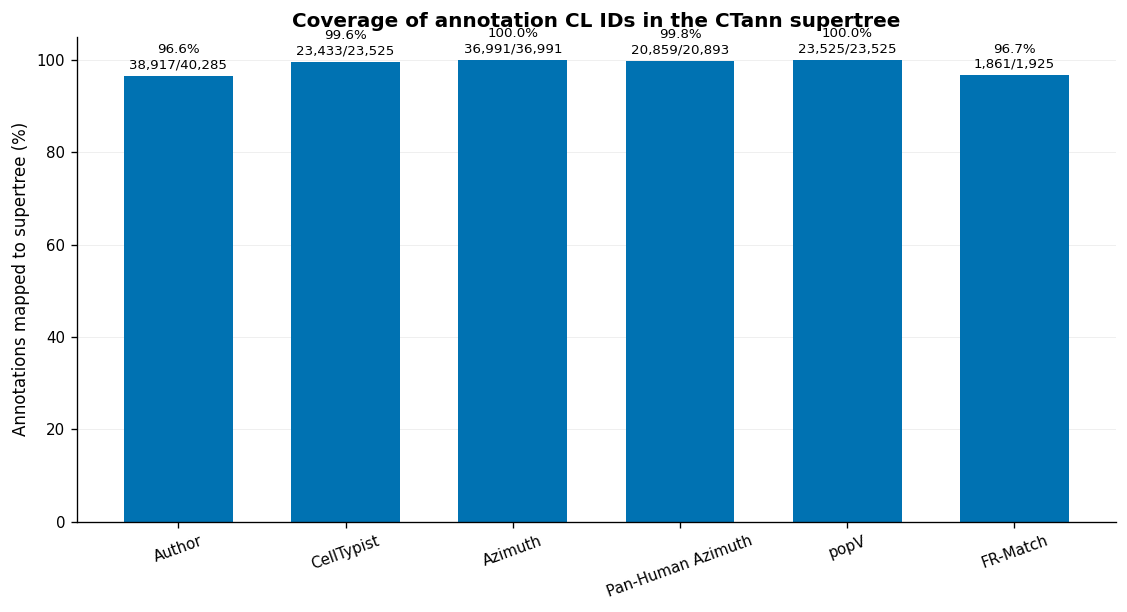

In [78]:
mapping_order = [
    "author",
    "celltypist",
    "azimuth",
    "pan-human-azimuth",
    "popv",
    "frmatch",
]


mapping_plot = (
    mapping_coverage[
        mapping_coverage[
            "tool"
        ].isin(
            mapping_order
        )
    ]
    .set_index("tool")
)


mapping_order = [
    tool
    for tool in mapping_order
    if tool
    in mapping_plot.index
]


mapping_plot = (
    mapping_plot
    .reindex(
        mapping_order
    )
)


values = (
    100
    * mapping_plot[
        "mapped_annotation_rate"
    ]
    .to_numpy(dtype=float)
)


labels = [
    TOOL_LABELS.get(
        tool,
        tool,
    )
    for tool
    in mapping_plot.index
]


fig, ax = plt.subplots(
    figsize=(9.5, 5.2)
)


bars = ax.bar(
    labels,
    values,
    color=COLORS["exact"],
    width=0.65,
)


ax.set_ylabel(
    "Annotations mapped to supertree (%)"
)

ax.set_ylim(
    0,
    105,
)

ax.set_title(
    "Coverage of annotation CL IDs in the CTann supertree"
)


ax.tick_params(
    axis="x",
    rotation=20,
)


ax.grid(
    axis="y",
    alpha=0.20,
)

ax.set_axisbelow(True)


for bar, (_, row) in zip(
    bars,
    mapping_plot.iterrows(),
):

    value = (
        bar.get_height()
    )

    mapped = int(
        row[
            "mapped_annotation_rows"
        ]
    )

    total = int(
        row[
            "annotation_rows"
        ]
    )


    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1.0,
        f"{value:.1f}%\n"
        f"{mapped:,}/{total:,}",
        ha="center",
        va="bottom",
        fontsize=8,
    )


fig.tight_layout()


fig.savefig(
    FIGURE_DIR
    / "05_supertree_mapping_coverage.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_DIR
    / "05_supertree_mapping_coverage.pdf",
    bbox_inches="tight",
)

plt.show()

In [80]:
check_labels = [
    "Kupffer cell",
    "mesangial cell",
    "type II pneumocyte",
    "glomerular visceral epithelial cell",
    "transformed epithelial cell",
]


check = level3[
    level3["author_label_original"].isin(
        check_labels
    )
][
    [
        "tool",
        "organ",
        "author_cl_id_original",
        "author_label_original",
        "author_mapping_status",
        "paired_cells",
        "exact_n",
        "narrower_n",
        "broader_n",
        "different_branch_n",
        "unmapped_n",
        "unmapped_rate",
        "hierarchy_compatible_rate",
    ]
].sort_values(
    [
        "author_label_original",
        "tool",
    ]
)


display(check)

,tool,organ,author_cl_id_original,author_label_original,author_mapping_status,paired_cells,exact_n,narrower_n,broader_n,different_branch_n,unmapped_n,unmapped_rate,hierarchy_compatible_rate
70,celltypist,UBERON:0002107,CL:0000091,Kupffer cell,UNMAPPED,623,0,0,0,0,623,1.000000,0.000000
108,pan-human-azimuth,UBERON:0002107,CL:0000091,Kupffer cell,UNMAPPED,428,0,0,0,0,428,1.000000,0.000000
160,popv,UBERON:0002107,CL:0000091,Kupffer cell,UNMAPPED,623,0,0,0,0,623,1.000000,0.000000
27,azimuth,UBERON:0002113,CL:0000653,glomerular visceral epithelial cell,MAPPED,463,446,0,0,17,0,0.000000,0.963283
117,pan-human-azimuth,UBERON:0002113,CL:0000653,glomerular visceral epithelial cell,MAPPED,48,44,0,0,4,0,0.000000,0.916667
29,azimuth,UBERON:0002113,CL:0000777,mesangial cell,UNMAPPED,239,0,0,0,0,239,1.000000,0.000000
119,pan-human-azimuth,UBERON:0002113,CL:0000777,mesangial cell,UNMAPPED,9,0,0,0,0,9,1.000000,0.000000
13,azimuth,UBERON:0002048,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,UNMAPPED,180,0,0,0,0,180,1.000000,0.000000
52,celltypist,UBERON:0002048,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,UNMAPPED,180,0,0,0,0,180,1.000000,0.000000
91,pan-human-azimuth,UBERON:0002048,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,UNMAPPED,58,0,0,0,0,58,1.000000,0.000000


In [82]:
sanity_labels = [
    "Kupffer cell",
    "mesangial cell",
    "transformed epithelial cell",
    "type II pneumocyte",
    "glomerular visceral epithelial cell",
]


display(
    level3_plot[
        level3_plot[
            "author_label_original"
        ].isin(sanity_labels)
    ][
        [
            "tool",
            "organ_name",
            "author_cl_id_original",
            "author_label_original",
            "paired_cells",
            "unmapped_rate",
            "hierarchy_compatible_rate",
        ]
    ]
    .sort_values(
        [
            "author_label_original",
            "tool",
        ]
    )
)

,tool,organ_name,author_cl_id_original,author_label_original,paired_cells,unmapped_rate,hierarchy_compatible_rate
70,celltypist,Liver,CL:0000091,Kupffer cell,623,1.000000,0.000000
108,pan-human-azimuth,Liver,CL:0000091,Kupffer cell,428,1.000000,0.000000
160,popv,Liver,CL:0000091,Kupffer cell,623,1.000000,0.000000
27,azimuth,Kidney,CL:0000653,glomerular visceral epithelial cell,463,0.000000,0.963283
117,pan-human-azimuth,Kidney,CL:0000653,glomerular visceral epithelial cell,48,0.000000,0.916667
29,azimuth,Kidney,CL:0000777,mesangial cell,239,1.000000,0.000000
119,pan-human-azimuth,Kidney,CL:0000777,mesangial cell,9,1.000000,0.000000
13,azimuth,Lung,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,180,1.000000,0.000000
52,celltypist,Lung,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,180,1.000000,0.000000
91,pan-human-azimuth,Lung,ASCTB-TEMP:transformed-epithelial-cell,transformed epithelial cell,58,1.000000,0.000000
